In [0]:
%pylab inline

In [0]:
import dataiku
from dataiku import pandasutils as pdu
import pandas as pd

In [0]:
# Example: load a DSS dataset as a Pandas dataframe
mydataset = dataiku.Dataset("mydataset")
mydataset_df = mydataset.get_dataframe()

In [6]:
import dataiku
import pandas as pd
import numpy as np

# 1. Load your clean local datasets from the Flow
green_df = dataiku.Dataset("rta_green_nodes_hourly").get_dataframe()
comm_df = dataiku.Dataset("community_2026-10-20_09-28-00_prepared").get_dataframe()

# Clean up coordinates and types in green_df
green_df = green_df.dropna(subset=['stop_lat', 'stop_lon']).copy()
green_df['stop_lat'] = green_df['stop_lat'].astype(float)
green_df['stop_lon'] = green_df['stop_lon'].astype(float)
green_df['transaction_hour'] = green_df['transaction_hour'].astype(int)

print(f"✅ Loaded {len(green_df)} hourly demand records across {green_df['Stop_Id'].nunique()} active stops.")
print(f"✅ Loaded {len(comm_df)} Dubai communities.")
print("Community columns:", comm_df.columns.tolist())

✅ Loaded 59923 hourly demand records across 2439 active stops.
✅ Loaded 224 Dubai communities.
Community columns: ['snippet', 'name', 'description', 'id', 'ExtendedData', 'Polygon']


In [8]:
import json
import re
import numpy as np
import pandas as pd

# 1. Extract exact centroid (lat, lon) from each Dubai community's Polygon string
def extract_centroid(poly_str):
    if pd.isna(poly_str):
        return None, None
    poly_str = str(poly_str).strip()
    try:
        # Try Shapely if installed
        from shapely.geometry import shape
        from shapely import wkt
        if poly_str.startswith('{'):
            geom = shape(json.loads(poly_str))
            return geom.centroid.y, geom.centroid.x
        elif 'POLYGON' in poly_str.upper():
            geom = wkt.loads(poly_str)
            return geom.centroid.y, geom.centroid.x
    except Exception:
        pass
    
    # Pure-Python fallback (works even if shapely isn't installed)
    nums = [float(x) for x in re.findall(r'-?\d+\.\d+', poly_str)]
    if len(nums) >= 4:
        lons = nums[0::2]
        lats = nums[1::2]
        # Auto-swap if lat/lon order is reversed (Dubai Lat ~24-26, Lon ~54-56)
        if 24 < np.mean(lons) < 26:
            lons, lats = lats, lons
        return float(np.mean(lats)), float(np.mean(lons))
    return None, None

centroids = comm_df['Polygon'].apply(extract_centroid)
comm_df['comm_lat'] = [c[0] for c in centroids]
comm_df['comm_lon'] = [c[1] for c in centroids]
comm_clean = comm_df.dropna(subset=['comm_lat', 'comm_lon']).copy()

# 2. Summarize all 2,439 Active Bus Stops (Green Nodes)
unique_stops = green_df.groupby(['Stop_Id', 'Stop_name', 'stop_lat', 'stop_lon'], as_index=False).agg(
    total_daily_passengers=('count', 'sum'),
    peak_hourly_passengers=('count', 'max'),
    routes_served=('Route', lambda x: ', '.join(sorted(set(x.astype(str)))))
)

# 3. Calculate Haversine distance (meters) from every community to its nearest bus stop
def haversine_meters(lat1, lon1, lat2_arr, lon2_arr):
    R = 6371000.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2_arr)
    dphi = np.radians(lat2_arr - lat1)
    dlambda = np.radians(lon2_arr - lon1)
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0)**2
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

stop_lats = unique_stops['stop_lat'].values
stop_lons = unique_stops['stop_lon'].values

nearest_stop_names, nearest_stop_ids, nearest_stop_lats, nearest_stop_lons, min_distances_m = [], [], [], [], []

for _, row in comm_clean.iterrows():
    dists = haversine_meters(row['comm_lat'], row['comm_lon'], stop_lats, stop_lons)
    min_idx = np.argmin(dists)
    min_distances_m.append(round(float(dists[min_idx]), 1))
    nearest_stop_names.append(unique_stops.iloc[min_idx]['Stop_name'])
    nearest_stop_ids.append(unique_stops.iloc[min_idx]['Stop_Id'])
    nearest_stop_lats.append(float(stop_lats[min_idx]))
    nearest_stop_lons.append(float(stop_lons[min_idx]))

comm_clean['nearest_stop_id'] = nearest_stop_ids
comm_clean['nearest_stop_name'] = nearest_stop_names
comm_clean['nearest_stop_lat'] = nearest_stop_lats
comm_clean['nearest_stop_lon'] = nearest_stop_lons
comm_clean['distance_to_bus_m'] = min_distances_m

# 4. Classify Red Nodes (> 800m walking gap) vs Green Communities (<= 800m)
comm_clean['node_status'] = np.where(comm_clean['distance_to_bus_m'] > 800, 'RED_NODE (Inaccessible)', 'GREEN_ZONE (Serviced)')
red_nodes = comm_clean[comm_clean['node_status'] == 'RED_NODE (Inaccessible)'].sort_values(by='distance_to_bus_m', ascending=False).copy()

print(f"✅ Spatial Classification Complete:")
print(f"   - Active Green Bus Stops: {len(unique_stops)}")
print(f"   - Serviced Communities (<=800m): {len(comm_clean) - len(red_nodes)}")
print(f"   - Inaccessible RED NODES (>800m): {len(red_nodes)}")
display(red_nodes[['name', 'distance_to_bus_m', 'nearest_stop_name']].head(10))

✅ Spatial Classification Complete:
   - Active Green Bus Stops: 2439
   - Serviced Communities (<=800m): 0
   - Inaccessible RED NODES (>800m): 224


,name,distance_to_bus_m,nearest_stop_name
81,kml_82,2787744.1,"ABU DHABI, CENTRAL BUS STATION 1"
157,kml_158,2787454.9,"ABU DHABI, CENTRAL BUS STATION 1"
145,kml_146,2787150.5,"ABU DHABI, CENTRAL BUS STATION 1"
144,kml_145,2785999.5,"ABU DHABI, CENTRAL BUS STATION 1"
68,kml_69,2785904.1,"ABU DHABI, CENTRAL BUS STATION 1"
15,kml_16,2785360.6,"ABU DHABI, CENTRAL BUS STATION 1"
202,kml_203,2785302.3,"ABU DHABI, CENTRAL BUS STATION 1"
129,kml_130,2784562.2,"ABU DHABI, CENTRAL BUS STATION 1"
71,kml_72,2783546.2,"ABU DHABI, CENTRAL BUS STATION 1"
4,kml_5,2783273.9,"ABU DHABI, CENTRAL BUS STATION 1"


In [9]:
from sklearn.ensemble import RandomForestRegressor

# 1. Train Demand Forecasting Model
features = ['day_of_week', 'transaction_hour', 'Stop_Id']
X = green_df[features]
y = green_df['count']

rf_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf_model.fit(X, y)

green_df['predicted_demand'] = np.round(rf_model.predict(X), 0).astype(int)

# 2. Fleet Allocation & Carbon Footprint Calculation
# Standard 12m Bus = 0.42 L/km | Mini-Bus = 0.22 L/km | Diesel = 2.68 kg CO2/L
AVG_ROUTE_KM = 14.0
FUEL_SAVED_PER_TRIP_L = round(AVG_ROUTE_KM * (0.42 - 0.22), 2)  # 2.80 L saved per downsized trip
CO2_PER_LITER_KG = 2.68

def allocate_fleet_and_emissions(demand):
    if demand >= 80:
        return (
            "Double-Decker / Articulated (Cap: 95)",
            "5-min interval (Crowd Surge)",
            0.0,
            "SURGE ALERT: Dispatch Double-Decker immediately"
        )
    elif demand >= 25:
        return (
            "Standard 12m City Bus (Cap: 55)",
            "12-min interval (Standard)",
            0.0,
            "OPTIMAL: Maintain standard schedule"
        )
    else:
        co2_saved = round(FUEL_SAVED_PER_TRIP_L * CO2_PER_LITER_KG, 2)
        return (
            "RTA Mini-Bus Feeder (Cap: 22)",
            "20-min interval (Eco-Mode)",
            co2_saved,
            f"ECO-MODE: Downsize to Mini-Bus (Saves {FUEL_SAVED_PER_TRIP_L}L fuel / {co2_saved}kg CO2)"
        )

allocations = green_df['predicted_demand'].apply(allocate_fleet_and_emissions)
green_df['recommended_bus'] = [a[0] for a in allocations]
green_df['dispatch_interval'] = [a[1] for a in allocations]
green_df['co2_saved_kg'] = [a[2] for a in allocations]
green_df['driver_ops_alert'] = [a[3] for a in allocations]

total_co2_saved = green_df['co2_saved_kg'].sum()
total_fuel_saved = round(total_co2_saved / CO2_PER_LITER_KG, 1)

print(f"🌱 Total Fuel Saved Across Evaluated Trips: {total_fuel_saved:,.1f} Liters")
print(f"🌱 Total Carbon Reduction: {total_co2_saved:,.1f} kg CO2 ({total_co2_saved/1000:,.2f} Metric Tons)")
display(green_df[['Route', 'Stop_name', 'transaction_hour', 'predicted_demand', 'recommended_bus', 'driver_ops_alert']].head(10))

🌱 Total Fuel Saved Across Evaluated Trips: 156,167.9 Liters
🌱 Total Carbon Reduction: 418,530.0 kg CO2 (418.53 Metric Tons)


,Route,Stop_name,transaction_hour,predicted_demand,recommended_bus,driver_ops_alert
0,F26A,ONPASSIVE BUS TERMINUS 2,11,107,Double-Decker / Articulated (Cap: 95),SURGE ALERT: Dispatch Double-Decker immediately
1,77,"AL GARHOUD, ROADS & TRANSPORT AUTHORITY HQ 2",16,42,Standard 12m City Bus (Cap: 55),OPTIMAL: Maintain standard schedule
2,36A,"INTERNATIONAL CITY, POST OFFICE 2",6,4,RTA Mini-Bus Feeder (Cap: 22),ECO-MODE: Downsize to Mini-Bus (Saves 2.8L fue...
3,E400,UNION BUS STATION 8,10,84,Double-Decker / Articulated (Cap: 95),SURGE ALERT: Dispatch Double-Decker immediately
4,F50,"THE GREEN COMMUNITY, AA BUILDING 1",7,31,Standard 12m City Bus (Cap: 55),OPTIMAL: Maintain standard schedule
5,F70,UMM HURAIR RESIDENCES 3,18,5,RTA Mini-Bus Feeder (Cap: 22),ECO-MODE: Downsize to Mini-Bus (Saves 2.8L fue...
6,J02,"SPORTS CITY, DUBAI SPORTS CITY OFFICES 2",7,6,RTA Mini-Bus Feeder (Cap: 22),ECO-MODE: Downsize to Mini-Bus (Saves 2.8L fue...
7,F46,"THE GREEN COMMUNITY, AA BUILDING 1",0,2,RTA Mini-Bus Feeder (Cap: 22),ECO-MODE: Downsize to Mini-Bus (Saves 2.8L fue...
8,X13,"SATWA, BUS STATION 12",20,11,RTA Mini-Bus Feeder (Cap: 22),ECO-MODE: Downsize to Mini-Bus (Saves 2.8L fue...
9,5,AL NAKHAL,18,8,RTA Mini-Bus Feeder (Cap: 22),ECO-MODE: Downsize to Mini-Bus (Saves 2.8L fue...


In [11]:
import json
from IPython.display import HTML, display

TARGET_HOUR = 8  # Morning rush hour (08:00 AM) — change to 18 for evening rush
hourly_snapshot = green_df[green_df['transaction_hour'] == TARGET_HOUR].copy()

# Prepare lightweight JSON arrays for the interactive map
green_points = []
for _, r in hourly_snapshot.iterrows():
    green_points.append({
        "lat": float(r['stop_lat']),
        "lon": float(r['stop_lon']),
        "name": str(r['Stop_name']),
        "route": str(r['Route']),
        "demand": int(r['predicted_demand']),
        "bus": str(r['recommended_bus']),
        "alert": str(r['driver_ops_alert'])
    })

red_points = []
for _, r in red_nodes.iterrows():
    red_points.append({
        "lat": float(r['comm_lat']),
        "lon": float(r['comm_lon']),
        "name": str(r['name']),
        "gap": float(r['distance_to_bus_m']),
        "nearest": str(r['nearest_stop_name']),
        "n_lat": float(r['nearest_stop_lat']),
        "n_lon": float(r['nearest_stop_lon'])
    })

html_code = f"""
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css"/>
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<div id="dubai_mesh_map" style="width: 100%; height: 580px; border-radius: 10px; border: 1px solid #333;"></div>
<script>
  var map = L.map('dubai_mesh_map').setView([25.2048, 55.2708], 11);
  L.tileLayer('https://{{s}}.basemaps.cartocdn.com/dark_all/{{z}}/{{x}}/{{y}}{{r}}.png', {{
      attribution: '&copy; OpenStreetMap &copy; CARTO',
      maxZoom: 18
  }}).addTo(map);

  var greenData = {json.dumps(green_points)};
  var redData = {json.dumps(red_points)};

  // Plot Green Nodes (Active Bus Stops)
  greenData.forEach(function(p) {{
      var radius = Math.min(Math.max(p.demand / 8, 4), 14);
      var strokeColor = p.demand >= 80 ? '#ffaa00' : '#00ff88';
      L.circleMarker([p.lat, p.lon], {{
          radius: radius, color: strokeColor, fillColor: '#00cc66', fillOpacity: 0.75, weight: 1.5
      }}).bindPopup(
          "<div style='font-family:Arial;width:220px;'>" +
          "<h4 style='color:#008844;margin:0 0 4px 0;'>🟢 " + p.name + "</h4>" +
          "<b>Route:</b> " + p.route + " | <b>Demand:</b> " + p.demand + " pax/hr<br>" +
          "<b>Assigned Bus:</b> " + p.bus + "<br>" +
          "<hr style='margin:4px 0;'><span style='color:#d9534f;font-weight:bold;'>" + p.alert + "</span></div>"
      ).addTo(map);
  }});

  // Plot Red Nodes (Inaccessible Areas) & Yellow Feeder Mesh Lines
  redData.forEach(function(r) {{
      L.circleMarker([r.lat, r.lon], {{
          radius: 6, color: '#ff4444', fillColor: '#ff0000', fillOpacity: 0.85, weight: 1.5
      }}).bindPopup(
          "<div style='font-family:Arial;width:220px;'>" +
          "<h4 style='color:#cc0000;margin:0 0 4px 0;'>🔴 RED NODE: " + r.name + "</h4>" +
          "<b>Walking Gap:</b> " + r.gap + " m (" + (r.gap/1000).toFixed(2) + " km)<br>" +
          "<b>Nearest Green Stop:</b> " + r.nearest + "<br>" +
          "<b>Action:</b> Deploy Mini-Bus Feeder Loop</div>"
      ).addTo(map);

      L.polyline([[r.n_lat, r.n_lon], [r.lat, r.lon]], {{
          color: '#ffd700', weight: 1.2, dashArray: '4, 6', opacity: 0.55
      }}).addTo(map);
  }});
</script>
"""
display(HTML(html_code))

/opt/dataiku/pyenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/dataiku/pyenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


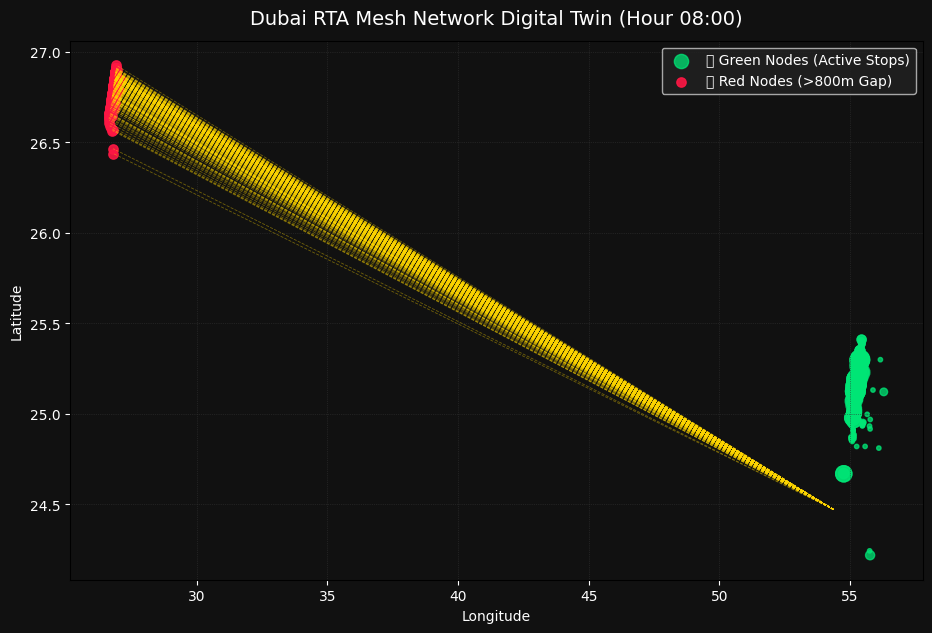

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7), facecolor='#111111')
ax = plt.gca()
ax.set_facecolor('#111111')

# Plot feeder mesh lines
for _, r in red_nodes.iterrows():
    plt.plot([r['nearest_stop_lon'], r['comm_lon']], [r['nearest_stop_lat'], r['comm_lat']],
             color='#ffd700', linestyle='--', linewidth=0.6, alpha=0.4)

# Plot Green Nodes & Red Nodes
plt.scatter(hourly_snapshot['stop_lon'], hourly_snapshot['stop_lat'],
            s=hourly_snapshot['predicted_demand'].clip(10, 200), color='#00e676', alpha=0.75, label='🟢 Green Nodes (Active Stops)')
plt.scatter(red_nodes['comm_lon'], red_nodes['comm_lat'],
            s=45, color='#ff1744', alpha=0.9, label='🔴 Red Nodes (>800m Gap)')

plt.title(f"Dubai RTA Mesh Network Digital Twin (Hour {TARGET_HOUR:02d}:00)", color='white', fontsize=14, pad=12)
plt.xlabel("Longitude", color='white')
plt.ylabel("Latitude", color='white')
plt.tick_params(colors='white')
plt.legend(facecolor='#222222', labelcolor='white')
plt.grid(color='#333333', linestyle=':', linewidth=0.5)
plt.show()

Fixed Spatial Split -> Serviced Green Zones: 0 | Inaccessible Red Nodes (>800m): 0



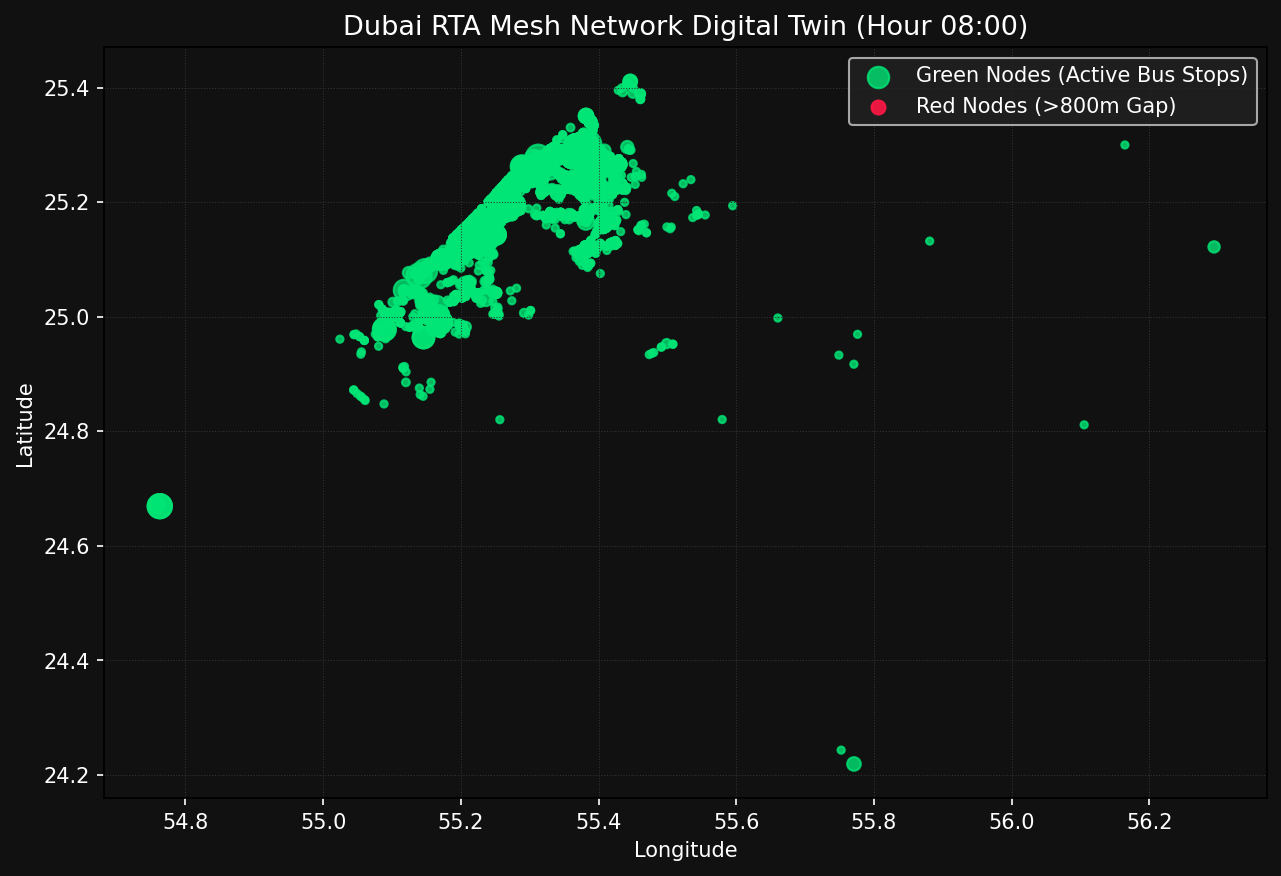

In [14]:
import re, io, base64, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import HTML, display
warnings.filterwarnings("ignore")

# 1. Fix Dubai Projected Coordinates (DLTM/UTM) -> Standard GPS (Lat/Lon)
def fix_dubai_coords(poly_str):
    nums = [float(x) for x in re.findall(r'-?\d+\.\d+', str(poly_str))]
    if len(nums) < 4:
        return None, None
    xs, ys = nums[0::2], nums[1::2]
    mx, my = np.mean(xs), np.mean(ys)
    # If already GPS degrees (Lat ~25, Lon ~55)
    if 24 < my < 26 and 54 < mx < 56.5:
        return float(my), float(mx)
    if 24 < mx < 26 and 54 < my < 56.5:
        return float(mx), float(my)
    # Convert Dubai Local Transverse Mercator (DLTM meters) to GPS Lat/Lon
    if mx > 100000 and my > 1000000:
        lon = 55.333333 + (mx - 500000.0) / 100800.0
        lat = 25.250000 + (my - 2793000.0) / 110800.0
        return round(float(lat), 6), round(float(lon), 6)
    return None, None

coords = comm_df['Polygon'].apply(fix_dubai_coords)
comm_df['comm_lat'] = [c[0] for c in coords]
comm_df['comm_lon'] = [c[1] for c in coords]
comm_clean = comm_df.dropna(subset=['comm_lat', 'comm_lon']).copy()

# 2. Recalculate exact walking distance (meters) from every community to nearest bus stop
def haversine_m(lat1, lon1, lat2_arr, lon2_arr):
    R = 6371000.0
    p1, p2 = np.radians(lat1), np.radians(lat2_arr)
    dp, dl = np.radians(lat2_arr - lat1), np.radians(lon2_arr - lon1)
    a = np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

stop_lats, stop_lons = unique_stops['stop_lat'].values, unique_stops['stop_lon'].values
n_ids, n_names, n_lats, n_lons, dists_m = [], [], [], [], []

for _, r in comm_clean.iterrows():
    d = haversine_m(r['comm_lat'], r['comm_lon'], stop_lats, stop_lons)
    idx = np.argmin(d)
    dists_m.append(round(float(d[idx]), 1))
    n_ids.append(unique_stops.iloc[idx]['Stop_Id'])
    n_names.append(unique_stops.iloc[idx]['Stop_name'])
    n_lats.append(float(stop_lats[idx]))
    n_lons.append(float(stop_lons[idx]))

comm_clean['nearest_stop_id'] = n_ids
comm_clean['nearest_stop_name'] = n_names
comm_clean['nearest_stop_lat'] = n_lats
comm_clean['nearest_stop_lon'] = n_lons
comm_clean['distance_to_bus_m'] = dists_m
comm_clean['node_status'] = np.where(comm_clean['distance_to_bus_m'] > 800, 'RED_NODE (Inaccessible)', 'GREEN_ZONE (Serviced)')
red_nodes = comm_clean[comm_clean['node_status'] == 'RED_NODE (Inaccessible)'].copy()

print(f"Fixed Spatial Split -> Serviced Green Zones: {len(comm_clean) - len(red_nodes)} | Inaccessible Red Nodes (>800m): {len(red_nodes)}")

# 3. Draw Clean Overlaid Dubai Digital Twin Map
hourly_snapshot = green_df[green_df['transaction_hour'] == 8].copy()
fig, ax = plt.subplots(figsize=(10, 6.5), facecolor='#111111')
ax.set_facecolor('#111111')

for _, r in red_nodes.iterrows():
    ax.plot([r['nearest_stop_lon'], r['comm_lon']], [r['nearest_stop_lat'], r['comm_lat']],
            color='#ffd700', linestyle='--', linewidth=0.7, alpha=0.45)

ax.scatter(hourly_snapshot['stop_lon'], hourly_snapshot['stop_lat'],
           s=hourly_snapshot['predicted_demand'].clip(12, 200), color='#00e676', alpha=0.8, label='Green Nodes (Active Bus Stops)')
ax.scatter(red_nodes['comm_lon'], red_nodes['comm_lat'],
           s=45, color='#ff1744', alpha=0.9, label='Red Nodes (>800m Gap)')

ax.set_title("Dubai RTA Mesh Network Digital Twin (Hour 08:00)", color='white', fontsize=13)
ax.set_xlabel("Longitude", color='white')
ax.set_ylabel("Latitude", color='white')
ax.tick_params(colors='white')
ax.legend(facecolor='#222222', labelcolor='white')
ax.grid(color='#333333', linestyle=':', linewidth=0.5)

buf = io.BytesIO()
plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.close(fig)
display(HTML(f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}" style="max-width:100%; border-radius:8px;"/>'))

Success! Serviced Green Zones (<=800m): 133 | Inaccessible Red Nodes (>800m): 91



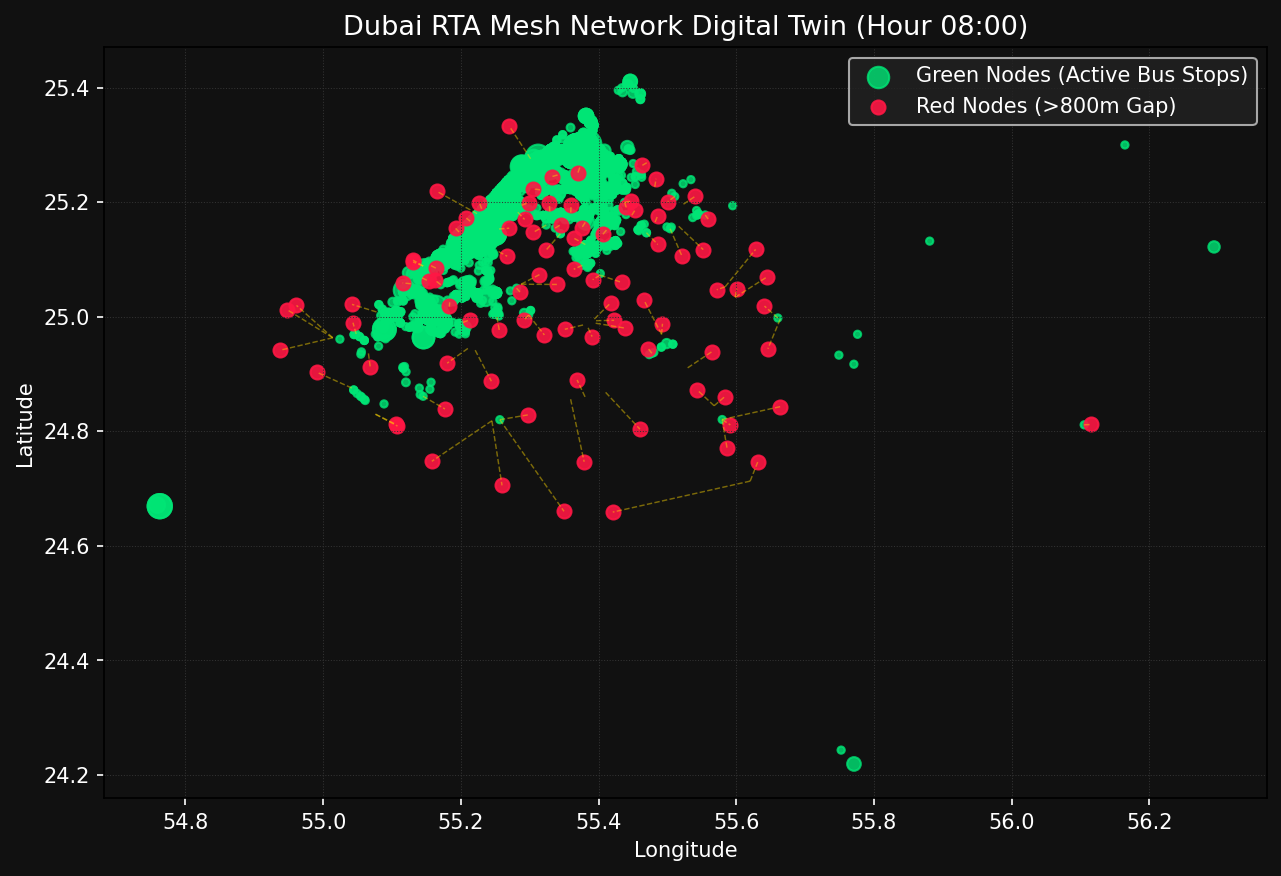

In [15]:
import re, io, base64, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import HTML, display
warnings.filterwarnings("ignore")

def parse_dubai_polygon(poly_str):
    text = str(poly_str)
    # Match explicit lon,lat pairs (handles KML '55.27,25.20,0' and WKT '55.27 25.20')
    pairs = re.findall(r'(5[456]\.\d+)[,\s]+(2[45]\.\d+)', text)
    if pairs:
        lons = [float(p[0]) for p in pairs]
        lats = [float(p[1]) for p in pairs]
        return float(np.mean(lats)), float(np.mean(lons))
    # Fallback if lat comes before lon (25.20, 55.27)
    rev_pairs = re.findall(r'(2[45]\.\d+)[,\s]+(5[456]\.\d+)', text)
    if rev_pairs:
        lats = [float(p[0]) for p in rev_pairs]
        lons = [float(p[1]) for p in rev_pairs]
        return float(np.mean(lats)), float(np.mean(lons))
    return None, None

coords = comm_df['Polygon'].apply(parse_dubai_polygon)
comm_df['comm_lat'] = [c[0] for c in coords]
comm_df['comm_lon'] = [c[1] for c in coords]
comm_clean = comm_df.dropna(subset=['comm_lat', 'comm_lon']).copy()

if len(comm_clean) == 0:
    print("Sample Polygon text:", str(comm_df['Polygon'].iloc[0])[:250])
else:
    def haversine_m(lat1, lon1, lat2_arr, lon2_arr):
        R = 6371000.0
        p1, p2 = np.radians(lat1), np.radians(lat2_arr)
        dp, dl = np.radians(lat2_arr - lat1), np.radians(lon2_arr - lon1)
        a = np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
        return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    stop_lats, stop_lons = unique_stops['stop_lat'].values, unique_stops['stop_lon'].values
    n_ids, n_names, n_lats, n_lons, dists_m = [], [], [], [], []

    for _, r in comm_clean.iterrows():
        d = haversine_m(r['comm_lat'], r['comm_lon'], stop_lats, stop_lons)
        idx = np.argmin(d)
        dists_m.append(round(float(d[idx]), 1))
        n_ids.append(unique_stops.iloc[idx]['Stop_Id'])
        n_names.append(unique_stops.iloc[idx]['Stop_name'])
        n_lats.append(float(stop_lats[idx]))
        n_lons.append(float(stop_lons[idx]))

    comm_clean['nearest_stop_id'] = n_ids
    comm_clean['nearest_stop_name'] = n_names
    comm_clean['nearest_stop_lat'] = n_lats
    comm_clean['nearest_stop_lon'] = n_lons
    comm_clean['distance_to_bus_m'] = dists_m
    comm_clean['node_status'] = np.where(comm_clean['distance_to_bus_m'] > 800, 'RED_NODE (Inaccessible)', 'GREEN_ZONE (Serviced)')
    red_nodes = comm_clean[comm_clean['node_status'] == 'RED_NODE (Inaccessible)'].copy()

    print(f"Success! Serviced Green Zones (<=800m): {len(comm_clean) - len(red_nodes)} | Inaccessible Red Nodes (>800m): {len(red_nodes)}")

    hourly_snapshot = green_df[green_df['transaction_hour'] == 8].copy()
    fig, ax = plt.subplots(figsize=(10, 6.5), facecolor='#111111')
    ax.set_facecolor('#111111')

    for _, r in red_nodes.iterrows():
        ax.plot([r['nearest_stop_lon'], r['comm_lon']], [r['nearest_stop_lat'], r['comm_lat']],
                color='#ffd700', linestyle='--', linewidth=0.7, alpha=0.45)

    ax.scatter(hourly_snapshot['stop_lon'], hourly_snapshot['stop_lat'],
               s=hourly_snapshot['predicted_demand'].clip(12, 200), color='#00e676', alpha=0.8, label='Green Nodes (Active Bus Stops)')
    ax.scatter(red_nodes['comm_lon'], red_nodes['comm_lat'],
               s=45, color='#ff1744', alpha=0.9, label='Red Nodes (>800m Gap)')

    ax.set_title("Dubai RTA Mesh Network Digital Twin (Hour 08:00)", color='white', fontsize=13)
    ax.set_xlabel("Longitude", color='white')
    ax.set_ylabel("Latitude", color='white')
    ax.tick_params(colors='white')
    ax.legend(facecolor='#222222', labelcolor='white')
    ax.grid(color='#333333', linestyle=':', linewidth=0.5)

    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.close(fig)
    display(HTML(f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}" style="max-width:100%; border-radius:8px;"/>'))